**Objetivo:** Calcular a conectividade funcional (correlação de Pearson, CC200) de cada participante.

**Entradas:** `Data/roi_timeseries/roi_timeseries_abide.pkl` (notebook 02).

**Processamento:** `ConnectivityMeasure(kind="correlation")` → matrizes 200×200; vetorização do triângulo superior sem diagonal (19.900 conexões).

**Saídas:** `Data/conectivity/connectivity_matrices_abide.pkl`, `Data/conectivity/connectivity_vectorized_abide.pkl`, `Figures/04_exemplo_matriz_conectividade.png`.

In [ ]:
# ------------------------------------------------------------
# Configuração do projeto (execução local — VS Code)
# Garante que a raiz do projeto esteja no sys.path, funcionando tanto se o
# diretório de trabalho do kernel for notebooks/ quanto a raiz do projeto.
# ------------------------------------------------------------
import sys
from pathlib import Path

_raiz = Path.cwd().resolve()
for _cand in (_raiz, *_raiz.parents):
    if (_cand / 'src' / 'config.py').exists():
        _raiz = _cand
        break
else:
    raise RuntimeError(
        'Não foi possível localizar a pasta src/config.py a partir de '
        f'{Path.cwd()}. Abra a pasta TCC_TEA_TDAH/ no VS Code.'
    )
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

import os
import random
import numpy as np

from src.config import BASE_DIR, PATHS, SEED, criar_pastas
from src.utils import exigir_arquivo

criar_pastas()

random.seed(SEED)
np.random.seed(SEED)

print('Projeto (BASE_DIR) =', BASE_DIR)

In [5]:
exigir_arquivo(PATHS['roi_timeseries'] / 'roi_timeseries_abide.pkl', '02_Download_ABIDE.ipynb')

import pickle
import numpy as np
import nilearn
from nilearn.connectome import ConnectivityMeasure

with open(os.path.join(PATHS['roi_timeseries'], 'roi_timeseries_abide.pkl'), 'rb') as f:
    roi_timeseries = pickle.load(f)

sub_ids = list(roi_timeseries.keys())
series_list = [roi_timeseries[s] for s in sub_ids]

print(f'{len(series_list)} sujeitos carregados para cálculo de conectividade.')

871 sujeitos carregados para cálculo de conectividade.


### Correlação de Pearson entre todas as ROIs, para cada sujeito

In [6]:
conn_measure = ConnectivityMeasure(kind='correlation')
connectivity_matrices = conn_measure.fit_transform(series_list)

print('Shape das matrizes de conectividade:', connectivity_matrices.shape)

Shape das matrizes de conectividade: (871, 200, 200)


### Salva as matrizes completas (200x200)

In [7]:
conn_dict = {sub_id: mat for sub_id, mat in zip(sub_ids, connectivity_matrices)}

out_path = os.path.join(PATHS['conectivity'], 'connectivity_matrices_abide.pkl')
with open(out_path, 'wb') as f:
    pickle.dump(conn_dict, f)

print('Matrizes salvas em:', out_path)

Matrizes salvas em: <BASE_DIR>/Data/conectivity/connectivity_matrices_abide.pkl


#### Vetorização: extrai o triângulo superior (sem diagonal) de cada matriz

In [8]:
from nilearn.connectome import sym_matrix_to_vec

vectorized = sym_matrix_to_vec(connectivity_matrices, discard_diagonal=True)
print('Shape vetorizado (N sujeitos x features):', vectorized.shape)

vec_dict = {sub_id: vec for sub_id, vec in zip(sub_ids, vectorized)}
out_path_vec = os.path.join(PATHS['conectivity'], 'connectivity_vectorized_abide.pkl')
with open(out_path_vec, 'wb') as f:
    pickle.dump(vec_dict, f)

print('Vetores salvos em:', out_path_vec)

Shape vetorizado (N sujeitos x features): (871, 19900)
Vetores salvos em: <BASE_DIR>/Data/conectivity/connectivity_vectorized_abide.pkl


#### Matriz de conectividade de um sujeito

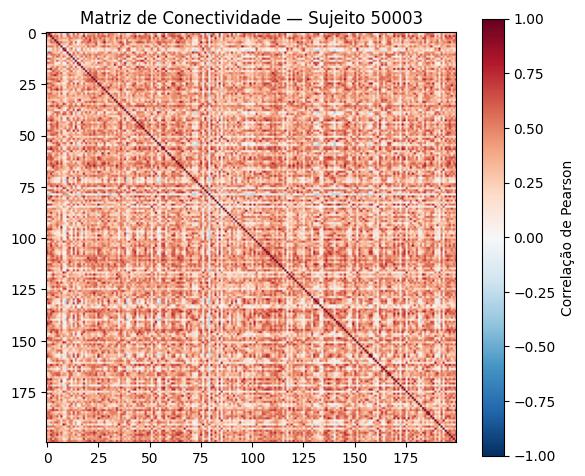

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(connectivity_matrices[0], vmin=-1, vmax=1, cmap='RdBu_r')
plt.colorbar(label='Correlação de Pearson')
plt.title(f'Matriz de Conectividade — Sujeito {sub_ids[0]}')
plt.tight_layout()
plt.savefig(os.path.join(PATHS['figures'], '04_exemplo_matriz_conectividade.png'), dpi=150)
plt.show()